# Stage 6 — Evaluation and error analysis

**Goal.** Compare all models on the same test set (MAE, RMSE, ±k accuracy, band accuracy / macro-F1, R²), compute BERT's MAE gain with paired bootstrap CIs, analyse errors by band and occupation, and run the probe, OCR-noise, sensitivity and fairness analyses.

Logic: `src/evaluation.py`, `src/visualization.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import utils

utils.set_seed()
print("SEED:", utils.SEED, "| device:", utils.get_device(), "| root:", utils.ROOT)

SEED: 42 | device: mps | root: /Users/michelle.li/Documents/HW_04_202602


All numbers come from `python -m src.evaluation`. It scores every model on the **same 600 test CVs, used here for the first time**, and writes the tables to `output/tables/`, the figures to `output/figures/` and a summary to `output/metrics/evaluation_summary.json`. Test predictions are cached in `output/predictions/`. Bootstraps use 2,000 paired resamples with seed 42.

The date rules are reported as an extra row: they are not a learned model, but they show the ceiling of the task.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

T = utils.TABLES_DIR
pd.set_option("display.max_colwidth", 160)

def show(name, w=16, h=5):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.imshow(plt.imread(utils.FIGURES_DIR / name))
    ax.axis("off")
    ax.grid(False)
    plt.show()

## Model comparison on the test set

**In plain words.**
- **Median:** off by 3.5 years on average, with no information.
- **Frozen embeddings:** 1.26 years. They capture what a CV is about, but not how long.
- **TF-IDF:** 0.84 years. It reads year tokens as words.
- **Fine-tuned BERT:** 0.25 years (about 3 months). 98.5% of its predictions are within ±1 year, every prediction is within ±2 years, and R² is 0.994.
- **Date rules:** 0.02 years, with no training at all.

BERT costs about 17 minutes of training on the M2 against seconds for the baselines. At inference it takes about 8 ms per CV, similar to the embedding model.

In [3]:
pd.read_csv(T / "model_comparison.csv")

,model,mae_years,rmse_years,acc_1,acc_2,acc_3,band_accuracy,band_macro_f1,r2,training_time_seconds,inference_time_per_cv_seconds
0,Median,3.5019,4.5355,0.1917,0.3400,0.5167,0.2883,0.1119,-0.0493,0.000586,0.000003
1,TF-IDF + Ridge,0.8360,1.0873,0.6750,0.9417,0.9883,0.8767,0.8798,0.9397,1.426630,0.000856
2,Embeddings + Ridge,1.2593,1.6398,0.4900,0.8200,0.9383,0.7783,0.7847,0.8628,9.232629,0.011529
3,Fine-tuned BERT,0.2508,0.3431,0.9850,1.0000,1.0000,0.9583,0.9601,0.9940,1017.305833,0.007572
4,Date rules (bonus),0.0229,0.0334,1.0000,1.0000,1.0000,0.9900,0.9903,0.9999,0.000000,0.000010


## Question 1a · How much does BERT gain, and is it real?

Paired bootstrap: the same resampled test CVs are scored by both models 2,000 times, giving a 95% interval for the MAE reduction. **BERT's gain is statistically meaningful against every learned baseline:**
- vs median: −3.25 years [3.03, 3.47];
- vs TF-IDF: −0.59 years [0.53, 0.64], a 70% lower error;
- vs embeddings: −1.01 years [0.93, 1.09].

None of the intervals comes close to 0.

**But BERT is significantly worse than simple date arithmetic:** +0.23 years [0.21, 0.25]. In PopResume, `exp_year` is exactly the sum of the job durations, and a regex computes that exactly while BERT only approximates it.

,baseline,baseline_mae,bert_mae,mae_reduction,relative_reduction,ci95_low,ci95_high,significant,conclusion
0,Median,3.5019,0.2508,3.2512,0.9284,3.0266,3.4733,True,BERT significantly better
1,TF-IDF + Ridge,0.8360,0.2508,0.5853,0.7001,0.5306,0.6394,True,BERT significantly better
2,Embeddings + Ridge,1.2593,0.2508,1.0085,0.8009,0.9275,1.0871,True,BERT significantly better
3,Date rules (bonus),0.0229,0.2508,-0.2279,-9.9562,-0.2468,-0.2096,True,BERT significantly worse


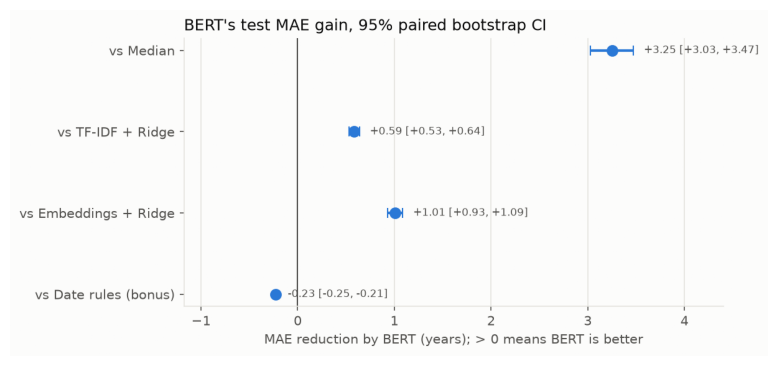

In [4]:
display(pd.read_csv(T / "bert_gain_bootstrap.csv"))
show("bert_gain.png", 10, 4.5)

## Predicted vs true: do models pull toward the middle?

**Why this chart.** Points on the dashed 45° line are perfect predictions. The orange fitted line shows the systematic pattern: a slope below 1 means juniors are overestimated and seniors underestimated, which is regression to the middle.

**What it shows.**
- **Embeddings** compress clearly: slope 0.86, seniors (11–20 years) underestimated by 1.35 years on average.
- **TF-IDF** compresses a little: slope 0.92, seniors −0.69.
- **BERT** does not compress: slope 0.99, and its small bias is a slight *overestimate* in every band (+0.2 years for juniors, +0.17 for seniors).
- **The rules** sit exactly on the line.

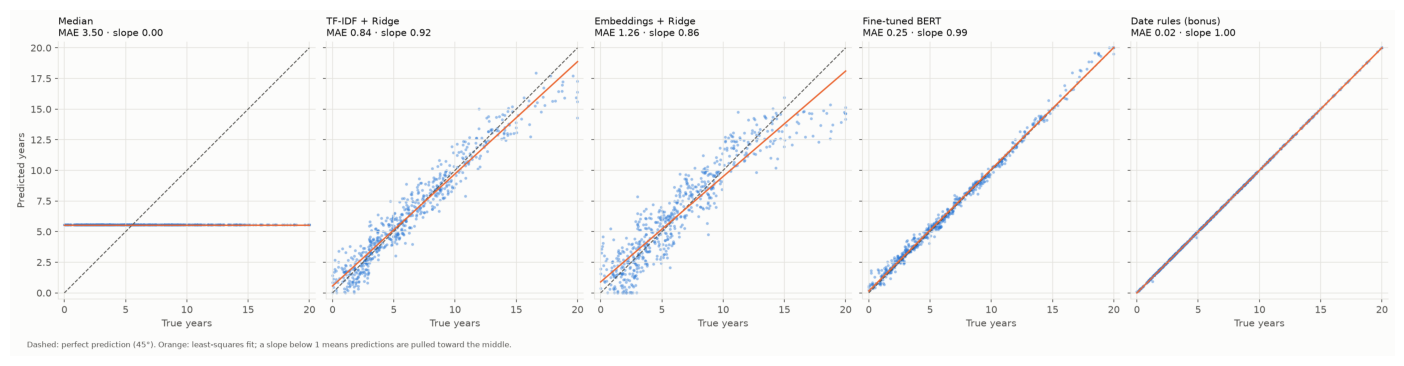

,model,slope_pred_on_true,intercept,mean_error_juniors_0_2,mean_error_seniors_11_20,compresses_to_middle
0,Median,0.0000,5.5441,3.7635,-8.8090,True
1,TF-IDF + Ridge,0.9158,0.5591,0.0100,-0.6910,False
2,Embeddings + Ridge,0.8607,0.8922,0.0822,-1.3532,True
3,Fine-tuned BERT,0.9937,0.1512,0.2080,0.1669,False
4,Date rules (bonus),1.0004,-0.0048,-0.0043,0.0011,False


In [5]:
show("pred_vs_true.png", 18, 4.5)
pd.read_csv(T / "compression_to_middle.csv")

## Question 1b · Where does BERT's gain come from?

**Why these charts.** Grouped bars put every model side by side in each experience band and each occupation, so you can see whether a gain is uniform or concentrated.

**What they show.**
- **Gain by band:** BERT's gain over TF-IDF is largest for **seniors** (1.16 → 0.29 years in the 11–20 band) and for juniors (0.78 → 0.30). Those are the extremes where the baselines are pulled toward the middle. Mid-career CVs gain too (0.80 → 0.19).
- **By occupation:** the picture is flat, with BERT between 0.22 and 0.29 years everywhere. The median baseline varies more by occupation (construction laborers have the most spread-out careers).
- **Bands:** BERT puts 92–98% of CVs in the right band (92% for 0–2 years). Its errors only spill into the neighbouring band, near the band edges.

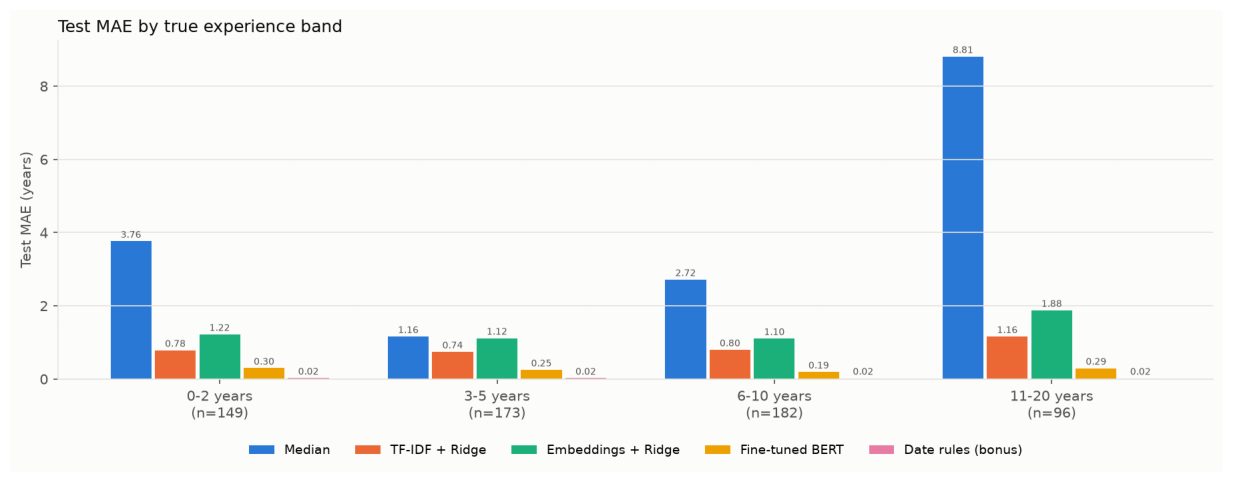

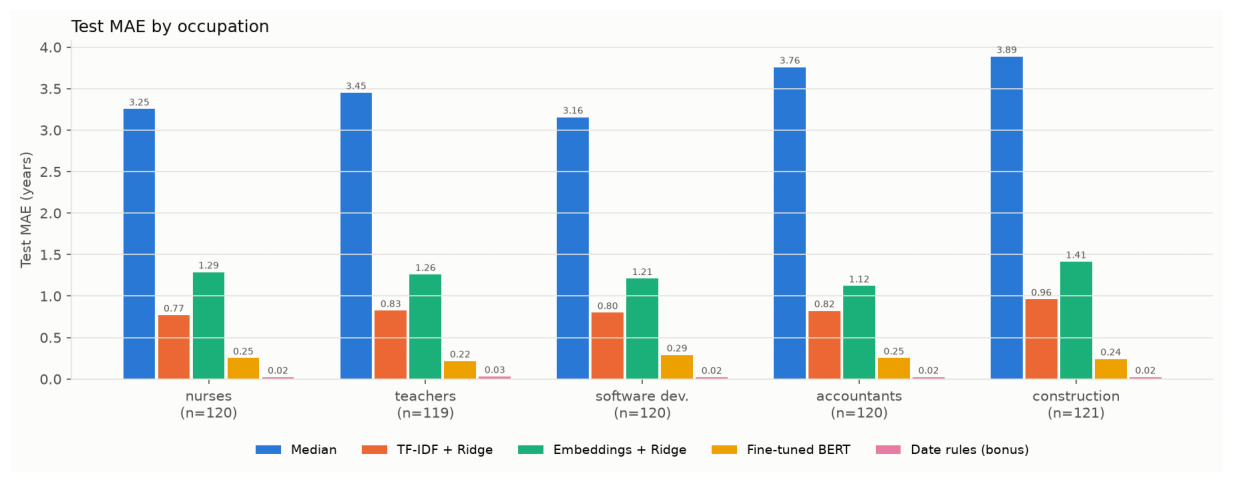

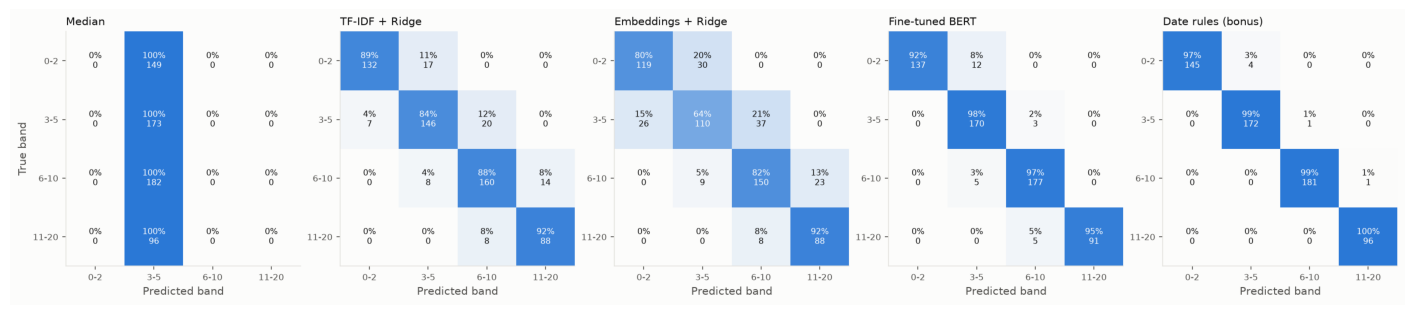

In [6]:
show("mae_by_band.png", 16, 6)
show("mae_by_occupation.png", 16, 6)
show("band_confusion.png", 18, 4)

## The 10 largest BERT errors

**All 10 are overestimates of about 1 to 1.6 years, and all 10 are career gaps.** The OCR read the dates correctly, nothing was truncated (no CV exceeds 162 tokens) and no jobs overlap. The rules get every one of these CVs right.

- **4 cases:** one short job (2–19 months) that ended around 2020, almost 3 years before the data snapshot (2023.01), with a much older graduation year. BERT predicts as if part of the time since then counted.
- **6 cases:** a gap of 0.8–2.5 years between two jobs. BERT predicts something between the true sum and the full first-start-to-last-end span.

**The pattern holds on the whole test set.**
- **Gap after the last job:** BERT's MAE doubles (0.43 vs 0.21) and it overestimates by +0.25 years.
- **Gaps between jobs:** BERT's MAE rises from 0.22 to 0.30.
- **TF-IDF** overestimates gap CVs even more (+0.50), because it reads the year range.
- **The rules** are unaffected.

**Possible improvements:**
- add the rules' output as an input feature, or train BERT on the residual of the rules;
- oversample CVs with gaps;
- try the Huber loss;
- give BERT normalised dates (e.g. months per job) instead of raw `YYYY.MM` strings.

In [7]:
top = pd.read_csv(T / "bert_top10_errors.csv", dtype={"id": str})
display(top.drop(columns="text"))
display(pd.read_csv(T / "error_by_career_pattern.csv"))
print(top.loc[0, "text"])

,id,occupation,y_true,bert_pred,rules_pred,error,n_jobs,cause,explanation
0,61082,registered_nurses,0.207,1.801,0.167,1.594,1,career gap,"The last job ended 2.9 years before the data snapshot (2023.01) and graduation was in 2009; BERT overestimates, as if part of the time since then counted as..."
1,31093,software_developers,0.214,1.602,0.250,1.389,1,career gap,"The last job ended 2.9 years before the data snapshot (2023.01) and graduation was in 2008; BERT overestimates, as if part of the time since then counted as..."
2,06678,accountants_auditors,16.623,17.953,16.583,1.330,4,career gap,"A 2.0-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
3,04004,software_developers,0.764,1.887,0.750,1.123,1,career gap,"The last job ended 2.8 years before the data snapshot (2023.01) and graduation was in 2016; BERT overestimates, as if part of the time since then counted as..."
4,61179,registered_nurses,18.461,19.574,18.500,1.113,4,career gap,"A 0.8-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
5,00508,registered_nurses,3.163,4.258,3.167,1.095,2,career gap,"A 0.9-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
6,26017,software_developers,3.093,4.174,3.083,1.081,2,career gap,"A 0.8-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
7,59706,accountants_auditors,3.699,4.740,3.667,1.042,2,career gap,"A 0.9-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
8,59496,construction_laborers,14.689,15.693,14.667,1.004,4,career gap,"A 2.5-year gap between jobs; BERT overestimates, as if it counted part of the span from first start to last end."
9,53786,construction_laborers,1.542,2.511,1.583,0.969,1,career gap,"The last job ended 3.0 years before the data snapshot (2023.01) and graduation was in 2011; BERT overestimates, as if part of the time since then counted as..."


,model,pattern,present,n,mae,mean_error
0,Median,gap_between_jobs,False,364,3.7281,-0.1050
1,Median,gap_between_jobs,True,236,3.1531,-2.3364
2,Median,last_job_ended_before_snapshot,False,490,3.6755,-1.8083
3,Median,last_job_ended_before_snapshot,True,110,2.7289,2.6955
4,TF-IDF + Ridge,gap_between_jobs,False,364,0.8045,-0.3058
5,TF-IDF + Ridge,gap_between_jobs,True,236,0.8847,0.4953
6,TF-IDF + Ridge,last_job_ended_before_snapshot,False,490,0.8268,-0.0209
7,TF-IDF + Ridge,last_job_ended_before_snapshot,True,110,0.8771,0.1441
8,Embeddings + Ridge,gap_between_jobs,False,364,1.3100,-0.3572
9,Embeddings + Ridge,gap_between_jobs,True,236,1.1810,0.5077


WORK HISTORY
Registered Nurses, ClearHands Nursing Group, 2019.12-2020.02
- Assisted with hygiene care
- Monitored intravenous lines
EDUCATION
Bachelor's, Health Promotion, Elmwood Ridge University, 2009
- Studied fundamentals of infection diseases nursing
Completed coursework in delegation principles


## Question 1c · Probe: does the model read dates or just vocabulary?

20 test CVs with at least two jobs. Two edits, with the rules giving the change a recruiter would expect:

- **(a) Delete one job.** The expected change is minus its duration: **−2.65 years** on average.
  - **BERT** moves in the right direction in 20/20 CVs, but only by −1.79 years.
  - **TF-IDF** moves by −1.15 years and **embeddings** by −1.72.
  - The correlation between each learned model's change and the deleted job's actual length is near 0 (BERT −0.07). They react to *one job fewer*, not to *how long that job was*.
- **(b) Shift every date by +5 years.** No CV says "Present", so durations do not change and the expected change is **0**.
  - **BERT** drops by **−1.45 years** on average.
  - **TF-IDF** and **embeddings** drop by about −0.55.
  - The rules do not move.

**Conclusion.** BERT reads dates much better than the baselines on normal CVs (0.25 vs 0.84 MAE), but the probe shows it has *not* learned the arithmetic.
- Part of what it knows is tied to the **absolute years**: later years mean less experience, because the data ends in 2023.01, so dates near 2023 signal a recent start.
- The rest is tied to the **number of job lines**.
- Shifting the dates into the future is out of distribution, and BERT fails there in a way a recruiter would not. Only the rules read dates the way a recruiter does.

In [8]:
display(pd.read_csv(T / "q1_probe_summary.csv"))
pd.read_csv(T / "q1_probe_predictions.csv", dtype={"id": str}).head()

,experiment,model,mean_expected_change,mean_model_change,mean_abs_deviation_from_expected,corr_with_expected,share_moving_right_direction
0,delete_one_job,Median,-2.65,0.0000,2.6500,NaN,0.00
1,delete_one_job,TF-IDF + Ridge,-2.65,-1.1477,1.5238,-0.0731,0.95
2,delete_one_job,Embeddings + Ridge,-2.65,-1.7212,1.1892,0.1416,0.90
3,delete_one_job,Fine-tuned BERT,-2.65,-1.7915,0.9676,-0.0720,1.00
4,delete_one_job,Date rules (bonus),-2.65,-2.6500,0.0000,1.0000,1.00
5,shift_plus_5_years,Median,0.00,0.0000,0.0000,NaN,NaN
6,shift_plus_5_years,TF-IDF + Ridge,0.00,-0.5760,2.0173,NaN,NaN
7,shift_plus_5_years,Embeddings + Ridge,0.00,-0.5407,2.3637,NaN,NaN
8,shift_plus_5_years,Fine-tuned BERT,0.00,-1.4486,1.6875,NaN,NaN
9,shift_plus_5_years,Date rules (bonus),0.00,0.0000,0.0000,NaN,NaN


,id,exp_year,median__original,median__delete_one_job,median__shift_plus_5_years,tfidf__original,tfidf__delete_one_job,tfidf__shift_plus_5_years,embeddings__original,embeddings__delete_one_job,embeddings__shift_plus_5_years,bert__original,bert__delete_one_job,bert__shift_plus_5_years,rules__original,rules__delete_one_job,rules__shift_plus_5_years
0,40829,15.168,5.544,5.544,5.544,14.483,13.854,10.893,13.676,14.145,11.680,15.121,14.599,10.168,15.167,11.417,15.167
1,02751,4.637,5.544,5.544,5.544,4.773,3.112,7.389,4.914,2.836,9.874,4.871,2.815,4.818,4.667,2.333,4.667
2,46225,11.777,5.544,5.544,5.544,11.860,10.363,8.554,10.803,8.039,8.338,11.492,9.147,9.722,11.750,8.833,11.750
3,55620,14.400,5.544,5.544,5.544,13.778,13.044,9.915,14.492,12.520,12.962,14.446,12.978,9.985,14.417,10.833,14.417
4,14022,8.868,5.544,5.544,5.544,10.483,9.066,8.374,9.691,7.570,7.130,9.105,6.656,7.101,8.833,5.917,8.833


## Question 2 · How much does OCR noise cost?

**OCR quality (stage 3):**
- CER 0.21% and WER 1.9%.
- The one systematic failure is the dropped dash in date ranges, so only 79.8% of years are found as is. After `repair_date_ranges`, 99.996% are found.
- The remaining errors are `i`→`l` in acronyms and dates cut off by the CV rendering itself.

**Cost for the models.** Every clean-trained model is scored on its test CVs twice: on the cleaned OCR text and on the cleaned reference text.
- **The gaps are tiny:** under 0.015 years for every model, and not significant for the baselines.
- **BERT is 0.007 years *better* on OCR text** than on the reference. That is significant but negligible. It was trained on OCR text, so the reference text is slightly out of its training distribution (for example, full `2023.01` dates where the images show `2023.`).
- **Most robust:** after the date repair, OCR noise costs essentially nothing. The bag-of-words and embedding models hardly care about single characters, and BERT and the rules see the same dates either way.

In [9]:
pd.read_csv(T / "q2_ocr_vs_reference.csv")

,model,mae_ocr_text,mae_reference_text,gap_ocr_minus_reference,ci95_low,ci95_high,significant
0,Median,3.5019,3.5019,0.0000,0.0000,0.0000,False
1,TF-IDF + Ridge,0.8360,0.8343,0.0017,-0.0009,0.0043,False
2,Embeddings + Ridge,1.2593,1.2454,0.0139,-0.0047,0.0326,False
3,Fine-tuned BERT,0.2508,0.2575,-0.0067,-0.0092,-0.0042,True
4,Date rules (bonus),0.0229,0.0217,0.0012,0.0000,0.0029,False


## Question 3 · Methodological sensitivity: raw vs cleaned OCR

Each model is trained and tested on each text variant:
- `raw`: no repair, so dates are still glued;
- `clean`;
- `clean_dropped_lowconf`: lines below 0.97 confidence removed. BERT was not trained on this variant.

**Results on test:**
- **BERT is the model most sensitive to cleaning:** 0.42 with raw vs 0.25 with clean (+0.17 years, paired bootstrap CI [0.14, 0.20]). On raw text it sees `2020.112023.01` as one long token sequence, and the arithmetic gets harder.
- **Embeddings** lose 0.08 years with raw (significant). **TF-IDF** barely changes (+0.01, not significant), because its character n-grams still catch the glued dates.
- **Dropping low-confidence lines** hurts slightly or not at all (TF-IDF +0.02, rules +0.015), as predicted in stage 3: those lines are correct, and 36 of them carry job dates.

**Is BERT's raw-vs-clean gap real or noise?** The paired bootstrap only covers *test-set* noise, and on that the gap is clearly significant. It does not cover *training* noise: each variant was trained once, and the validation MAE moved by 0.05–0.2 years between consecutive epochs (raw: 0.40 → 0.61 → 0.46). The raw run also stopped at epoch 2, while clean stopped at epoch 4. So the direction is credible (cleaning helps, and the mechanism is clear), but the size of the gap should be confirmed by retraining both variants with 2–3 seeds before it is stated as a fact.

In [10]:
display(pd.read_csv(T / "q3_variant_mae.csv"))
pd.read_csv(T / "q3_variant_bootstrap.csv")

,model,raw,clean,clean_dropped_lowconf
0,Median,3.5019,3.5019,3.5019
1,TF-IDF + Ridge,0.8470,0.8360,0.8610
2,Embeddings + Ridge,1.3345,1.2593,1.2685
3,Fine-tuned BERT,0.4216,0.2508,NaN
4,Date rules (bonus),0.0229,0.0229,0.0381


,model,comparison,mae_variant,mae_clean,diff,ci95_low,ci95_high,significant
0,Median,raw - clean,3.5019,3.5019,0.0000,0.0000,0.0000,False
1,Median,clean_dropped_lowconf - clean,3.5019,3.5019,0.0000,0.0000,0.0000,False
2,TF-IDF + Ridge,raw - clean,0.8470,0.8360,0.0110,-0.0136,0.0367,False
3,TF-IDF + Ridge,clean_dropped_lowconf - clean,0.8610,0.8360,0.0249,0.0010,0.0481,True
4,Embeddings + Ridge,raw - clean,1.3345,1.2593,0.0752,0.0309,0.1200,True
5,Embeddings + Ridge,clean_dropped_lowconf - clean,1.2685,1.2593,0.0093,-0.0200,0.0388,False
6,Fine-tuned BERT,raw - clean,0.4216,0.2508,0.1709,0.1428,0.2008,True
7,Date rules (bonus),raw - clean,0.0229,0.0229,0.0000,0.0000,0.0000,False
8,Date rules (bonus),clean_dropped_lowconf - clean,0.0381,0.0229,0.0152,0.0033,0.0322,True


## Question 4 · Fairness check (sex and race are not model inputs)

**BERT's mean error (predicted − true) by group, with 95% bootstrap CIs.** BERT slightly overestimates every group except Black candidates:

| Group | n | Mean error (years) | 95% CI |
|---|---|---|---|
| Female | 299 | +0.08 | [0.05, 0.13] |
| Male | 301 | +0.14 | [0.10, 0.17] |
| Asian/Pacific Islander | 91 | +0.15 | [0.09, 0.22] |
| White | 462 | +0.11 | [0.09, 0.14] |
| Black | 47 | −0.02 | [−0.12, 0.07] |

- **MAE is the same across all groups (0.24–0.26).**
- The sex intervals overlap. The Asian/PI vs Black difference is about 0.18 years (2 months), with only 47 Black candidates in the test set.
- **The date rules show no group difference at all** (mean errors within ±0.004 years).

**What could explain the differences when sex and race are not inputs?** Group membership correlates with career patterns in this population-based data, and BERT's bias depends on those patterns. Its largest overestimates are careers with a gap after the last job, and men have that pattern more often (19.9% vs 16.7%). The groups also differ in average experience (Asian/PI 7.5 years vs White 6.3). Names, which could reveal sex or race, are removed before modelling. The differences are small compared with the overall error, but **a model can pick up group-correlated proxies even without the attributes**, so this check must be repeated on real data.

,model,attribute,group,n,mae,mae_ci95_low,mae_ci95_high,mean_error,mean_error_ci95_low,mean_error_ci95_high,mean_true_years
0,Fine-tuned BERT,sex,Female,299,0.2501,0.2233,0.2797,0.0846,0.0489,0.1260,6.8466
1,Fine-tuned BERT,sex,Male,301,0.2514,0.2257,0.2777,0.1354,0.0989,0.1706,6.2089
2,Fine-tuned BERT,race,Asian/Pacific Islander,91,0.2609,0.2162,0.3091,0.1546,0.0937,0.2210,7.4692
3,Fine-tuned BERT,race,Black,47,0.2443,0.1844,0.3087,-0.0229,-0.1155,0.0730,6.6189
4,Fine-tuned BERT,race,White,462,0.2494,0.2286,0.2709,0.1149,0.0852,0.1449,6.3317
5,Date rules (bonus),sex,Female,299,0.0248,0.0218,0.0291,-0.0035,-0.0083,0.0007,6.8466
6,Date rules (bonus),sex,Male,301,0.0210,0.0195,0.0225,-0.0010,-0.0037,0.0017,6.2089
7,Date rules (bonus),race,Asian/Pacific Islander,91,0.0189,0.0165,0.0215,0.0015,-0.0031,0.0062,7.4692
8,Date rules (bonus),race,Black,47,0.0193,0.0155,0.0233,0.0034,-0.0033,0.0104,6.6189
9,Date rules (bonus),race,White,462,0.0240,0.0218,0.0267,-0.0036,-0.0072,-0.0005,6.3317


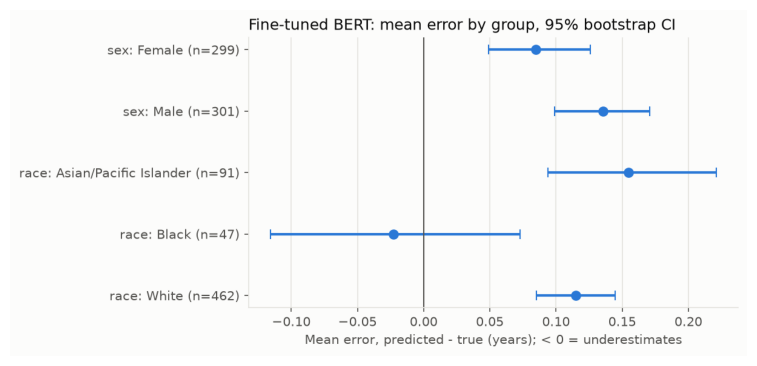

In [11]:
display(pd.read_csv(T / "q4_fairness.csv"))
show("q4_fairness.png", 10, 4.5)

## Question 4 · Business value and limits

- **Who could use it.** Recruiting agencies, job boards, public employment services and HR teams. The right task is **pre-filling a profile field** ("years of experience: ~6") that a person confirms, not **deciding who gets an interview**.
- **What an error costs.** ±2 years rarely matters for a profile field. It matters at thresholds ("5+ years required"): a 4.5-year candidate predicted at 5.5 gets through, and the reverse silently filters someone out. Underestimating is worse for the candidate (hidden rejection); overestimating is worse for the employer (mismatched interviews). A screening use should therefore always show the extracted dates, not just a number.
- **Is BERT worth it?** Against the learned baselines, clearly yes: 0.25 vs 0.84 years MAE, a significant 70% reduction, with no compression toward the middle, for about 17 minutes of training on a laptop and 8 ms per CV. **Against date arithmetic, no:** on this data the rules are 10× more accurate, instantaneous and fully explainable. The probe shows BERT has not truly learned to read dates. The best system would combine both: rules for well-formatted CVs, a learned model for messy text where the regex finds no clean date ranges.
- **Limitations:**
  - synthetic resumes from a single template, all one column, with the target defined exactly by the listed dates;
  - only 5 occupations and U.S. statistics, English only;
  - one training run per variant.

  Real CVs have free-form dates ("since 2019", "3 yrs"), overlapping and part-time jobs, and multi-column layouts, so these numbers are an upper bound. **Such a system must never decide on its own who is hired.**